In [1]:
%pip install -q ucimlrepo shap

# Checking the data

In [2]:

from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np

# Fetch the UCI Phishing Websites dataset
phishing_data = fetch_ucirepo(id=327)

# Separate input features and target
X = phishing_data.data.features
y = phishing_data.data.targets

# Combine them for initial exploration
df = pd.concat([X, y], axis=1)

print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame(name="Data Type"))

print("\nTarget distribution:")
display(y.value_counts(dropna=False).to_frame(name="Count"))

print("\nMissing values per column:")
display(df.isnull().sum().to_frame(name="Missing Values"))

print("\nExact duplicate rows:", df.duplicated().sum())


Dataset shape: (11055, 31)

First 5 rows:


,having_ip_address,url_length,shortining_service,having_at_symbol,double_slash_redirecting,prefix_suffix,having_sub_domain,sslfinal_state,domain_registration_length,favicon,...,popupwindow,iframe,age_of_domain,dnsrecord,web_traffic,page_rank,google_index,links_pointing_to_page,statistical_report,result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1



Column names:
['having_ip_address', 'url_length', 'shortining_service', 'having_at_symbol', 'double_slash_redirecting', 'prefix_suffix', 'having_sub_domain', 'sslfinal_state', 'domain_registration_length', 'favicon', 'port', 'https_token', 'request_url', 'url_of_anchor', 'links_in_tags', 'sfh', 'submitting_to_email', 'abnormal_url', 'redirect', 'on_mouseover', 'rightclick', 'popupwindow', 'iframe', 'age_of_domain', 'dnsrecord', 'web_traffic', 'page_rank', 'google_index', 'links_pointing_to_page', 'statistical_report', 'result']

Data types:


,Data Type
having_ip_address,int64
url_length,int64
shortining_service,int64
having_at_symbol,int64
double_slash_redirecting,int64
prefix_suffix,int64
having_sub_domain,int64
sslfinal_state,int64
domain_registration_length,int64
favicon,int64



Target distribution:


,Count
result,
1,6157
-1,4898



Missing values per column:


,Missing Values
having_ip_address,0
url_length,0
shortining_service,0
having_at_symbol,0
double_slash_redirecting,0
prefix_suffix,0
having_sub_domain,0
sslfinal_state,0
domain_registration_length,0
favicon,0



Exact duplicate rows: 5206


# investigating the duplicates

In [3]:

# Step 2: Duplicate and target-label investigation

import pandas as pd

X = phishing_data.data.features.copy()
y = phishing_data.data.targets.iloc[:, 0].copy()

print("=" * 55)
print("1. DATASET SIZE")
print("=" * 55)
print("Total rows:", len(X))
print("Number of features:", X.shape[1])

# A. Duplicate feature vectors, ignoring the target
print("\n" + "=" * 55)
print("2. DUPLICATE FEATURE VECTORS")
print("=" * 55)

duplicate_features = X.duplicated(keep=False)
print("Rows belonging to repeated feature vectors:",
      duplicate_features.sum())
print("Repeated feature vectors after first occurrence:",
      X.duplicated().sum())

# B. Check whether identical feature vectors have different labels
print("\n" + "=" * 55)
print("3. CONFLICTING LABELS")
print("=" * 55)

feature_groups = X.copy()
feature_groups["_target"] = y.to_numpy()

labels_per_feature_vector = (
    feature_groups.groupby(list(X.columns), dropna=False)["_target"]
    .nunique()
)

conflicting_vectors = labels_per_feature_vector[
    labels_per_feature_vector > 1
]

print("Feature vectors with conflicting labels:",
      len(conflicting_vectors))

# C. Target label counts and proportions
print("\n" + "=" * 55)
print("4. TARGET LABEL DISTRIBUTION")
print("=" * 55)

target_summary = pd.DataFrame({
    "Count": y.value_counts(),
    "Percentage": y.value_counts(normalize=True).mul(100).round(2)
})

display(target_summary.sort_index())

# D. Inspect examples of repeated feature vectors
print("\n" + "=" * 55)
print("5. EXAMPLES OF DUPLICATE FEATURE VECTORS")
print("=" * 55)

if duplicate_features.any():
    duplicate_examples = feature_groups.loc[
        duplicate_features
    ].sort_values(by=list(X.columns)).head(10)

    display(duplicate_examples)
else:
    print("No duplicate feature vectors found.")


1. DATASET SIZE
Total rows: 11055
Number of features: 30

2. DUPLICATE FEATURE VECTORS
Rows belonging to repeated feature vectors: 7884
Repeated feature vectors after first occurrence: 5270

3. CONFLICTING LABELS
Feature vectors with conflicting labels: 64

4. TARGET LABEL DISTRIBUTION


,Count,Percentage
result,,
-1,4898,44.31
1,6157,55.69



5. EXAMPLES OF DUPLICATE FEATURE VECTORS


,having_ip_address,url_length,shortining_service,having_at_symbol,double_slash_redirecting,prefix_suffix,having_sub_domain,sslfinal_state,domain_registration_length,favicon,...,popupwindow,iframe,age_of_domain,dnsrecord,web_traffic,page_rank,google_index,links_pointing_to_page,statistical_report,_target
9027,-1,-1,-1,-1,-1,-1,-1,-1,-1,1,...,-1,1,1,-1,0,-1,1,1,1,-1
9422,-1,-1,-1,-1,-1,-1,-1,-1,-1,1,...,-1,1,1,-1,0,-1,1,1,1,-1
7022,-1,-1,-1,-1,-1,-1,0,-1,-1,-1,...,-1,1,-1,-1,0,-1,-1,1,1,-1
7243,-1,-1,-1,-1,-1,-1,0,-1,-1,-1,...,-1,1,-1,-1,0,-1,-1,1,1,-1
10033,-1,-1,-1,-1,-1,-1,0,-1,-1,-1,...,-1,1,1,-1,0,-1,1,1,1,-1
10168,-1,-1,-1,-1,-1,-1,0,-1,-1,-1,...,-1,1,1,-1,0,-1,1,1,1,-1
5495,-1,-1,-1,-1,-1,-1,0,-1,-1,-1,...,-1,1,-1,-1,0,1,-1,0,1,-1
7672,-1,-1,-1,-1,-1,-1,0,-1,-1,-1,...,-1,1,-1,-1,0,1,-1,0,1,-1
8536,-1,-1,-1,-1,-1,-1,0,-1,-1,-1,...,-1,1,1,-1,1,-1,1,0,-1,-1
10579,-1,-1,-1,-1,-1,-1,0,-1,-1,-1,...,-1,1,1,-1,1,-1,1,0,-1,-1


In [4]:

# Step 2B: Inspect actual duplicate groups

X = phishing_data.data.features.copy()
y = phishing_data.data.targets.iloc[:, 0].copy()

# Group identical feature vectors, regardless of target
grouped = X.copy()
grouped["_target"] = y.to_numpy()

grouped["feature_group_id"] = (
    X.groupby(list(X.columns), sort=False, dropna=False)
    .ngroup()
    .to_numpy()
)

# Keep only groups containing multiple rows
group_sizes = grouped["feature_group_id"].value_counts()
repeated_ids = group_sizes[group_sizes > 1].index

repeated_groups = grouped[
    grouped["feature_group_id"].isin(repeated_ids)
].sort_values("feature_group_id")

print("Number of repeated feature-vector groups:",
      len(repeated_ids))

print("\nRows in repeated groups:", len(repeated_groups))

# Inspect one real duplicate group
example_id = repeated_ids[0]
example_group = repeated_groups[
    repeated_groups["feature_group_id"] == example_id
]

print(f"\nExample duplicate group ID: {example_id}")
print("Rows in this group:", len(example_group))
display(example_group)

# Check target-label consistency across all groups
labels_per_group = grouped.groupby("feature_group_id")["_target"].nunique()

print("\nGroups with conflicting target labels:",
      (labels_per_group > 1).sum())

print("\nDistribution of repeated group sizes:")
display(group_sizes[group_sizes > 1].value_counts().sort_index()
        .rename_axis("Rows per group")
        .to_frame("Number of groups"))


Number of repeated feature-vector groups: 2614

Rows in repeated groups: 7884

Example duplicate group ID: 400
Rows in this group: 25


,having_ip_address,url_length,shortining_service,having_at_symbol,double_slash_redirecting,prefix_suffix,having_sub_domain,sslfinal_state,domain_registration_length,favicon,...,iframe,age_of_domain,dnsrecord,web_traffic,page_rank,google_index,links_pointing_to_page,statistical_report,_target,feature_group_id
410,1,-1,1,1,1,-1,1,1,-1,1,...,1,1,1,1,-1,1,0,1,1,400
3169,1,-1,1,1,1,-1,1,1,-1,1,...,1,1,1,1,-1,1,0,1,1,400
4003,1,-1,1,1,1,-1,1,1,-1,1,...,1,1,1,1,-1,1,0,1,1,400
9615,1,-1,1,1,1,-1,1,1,-1,1,...,1,1,1,1,-1,1,0,1,1,400
8274,1,-1,1,1,1,-1,1,1,-1,1,...,1,1,1,1,-1,1,0,1,1,400
8638,1,-1,1,1,1,-1,1,1,-1,1,...,1,1,1,1,-1,1,0,1,1,400
2878,1,-1,1,1,1,-1,1,1,-1,1,...,1,1,1,1,-1,1,0,1,1,400
1483,1,-1,1,1,1,-1,1,1,-1,1,...,1,1,1,1,-1,1,0,1,1,400
431,1,-1,1,1,1,-1,1,1,-1,1,...,1,1,1,1,-1,1,0,1,1,400
8444,1,-1,1,1,1,-1,1,1,-1,1,...,1,1,1,1,-1,1,0,1,1,400



Groups with conflicting target labels: 64

Distribution of repeated group sizes:


,Number of groups
Rows per group,
2,1487
3,423
4,437
5,89
6,63
7,30
8,32
9,20
10,14


# Dealing with the diffrent kinds of duplicates

In [5]:
# Step 1: Remove rows that are identical across all columns
rows_before = len(df)

df_clean = df.drop_duplicates().reset_index(drop=True)

rows_after = len(df_clean)
rows_removed = rows_before - rows_after

print(f"Rows before removing duplicates: {rows_before}")
print(f"Rows after removing duplicates:  {rows_after}")
print(f"Complete duplicate rows removed: {rows_removed}")
print(f"Remaining duplicate rows:         {df_clean.duplicated().sum()}")

Rows before removing duplicates: 11055
Rows after removing duplicates:  5849
Complete duplicate rows removed: 5206
Remaining duplicate rows:         0


In [6]:
# The 30 input features, excluding the target
feature_cols = X.columns.tolist()

# Keep every row whose feature combination occurs more than once
same_features = df_clean[
    df_clean.duplicated(subset=feature_cols, keep=False)
].copy()

# Count each result value within each identical feature group
conflict_counts = (
    same_features
    .groupby(feature_cols, dropna=False)["result"]
    .value_counts()
    .unstack(fill_value=0)
)

# Keep only groups with more than one distinct result
conflict_counts = conflict_counts[
    (conflict_counts > 0).sum(axis=1) > 1
]

print("Conflicting feature groups:", len(conflict_counts))
print("Rows belonging to conflicting groups:", int(conflict_counts.sum().sum()))

display(conflict_counts.head(10))

Conflicting feature groups: 64
Rows belonging to conflicting groups: 128


result                                                                                                                                                                                                                                                                                                                                                                                                                              -1  \
having_ip_address url_length shortining_service having_at_symbol double_slash_redirecting prefix_suffix having_sub_domain sslfinal_state domain_registration_length favicon port https_token request_url url_of_anchor links_in_tags sfh submitting_to_email abnormal_url redirect on_mouseover rightclick popupwindow iframe age_of_domain dnsrecord web_traffic page_rank google_index links_pointing_to_page statistical_report       
-1                -1         1                  1                1                        -1            -1                 1             -1                         1       1    1            1          0              0            -1  1                   1            0        1            1          1           1      -1            1          0           1        1            0                      1                    1   
                                                                                                         0                -1              1                         1       1    1           -1          0             -1            -1  1                   1            0        1            1          1           1      -1            1          1          -1        1            1                      1                    1   
                                                                                                                                                                                                                                                                                                                                                                   1        1            1                      1                    1   
                                                                                                                                                                                                                        0            -1  1                   1            0        1            1          1           1      -1            1          1          -1        1            1                      1                    1   
                                                                                                                           1             -1                         1       1    1            1          0              0            -1  1                   1            0        1            1          1           1      -1            1          1          -1        1            0                      1                    1   
                                                                                                                                                                                                                                                                                                                               1            1          1          -1        1            0                      1                    1   
                                                                                                                                          1                         1       1    1            1          0              0            -1  1                   1            0        1            1          1           1      -1            1          0           1        1            1                      1                    1   
                                                                                                                                                                      

In [7]:
# Count each label in every conflicting feature group
label_counts = (
    same_features
    .groupby(feature_cols, dropna=False)["result"]
    .value_counts()
    .unstack(fill_value=0)
)

# Keep groups with conflicting labels
conflicts = label_counts[
    (label_counts > 0).sum(axis=1) > 1
]

print("Number of conflicting groups:", len(conflicts))
print("\nLabel-count combinations:")
display(
    conflicts.value_counts()
    .rename("number_of_groups")
    .reset_index()
)

print("\nAre all groups exactly one -1 and one +1?")
print(
    ((conflicts[-1] == 1) & (conflicts[1] == 1)).all()
)

Number of conflicting groups: 64

Label-count combinations:


,-1,1,number_of_groups
0,1,1,64



Are all groups exactly one -1 and one +1?
True


In [8]:
# Step 1: Identify feature combinations with conflicting labels
label_counts = (
    df_clean
    .groupby(feature_cols, dropna=False)["result"]
    .nunique()
)

conflicting_features = label_counts[label_counts > 1].index

# Step 2: Remove every row belonging to a conflicting feature group
conflict_index = pd.MultiIndex.from_frame(
    df_clean[feature_cols]
)

rows_before = len(df_clean)

df_clean = df_clean.loc[
    ~conflict_index.isin(conflicting_features)
].reset_index(drop=True)

rows_removed = rows_before - len(df_clean)

# Step 3: Verify the results
print(f"Rows before removing conflicts: {rows_before}")
print(f"Rows removed:                   {rows_removed}")
print(f"Rows remaining:                 {len(df_clean)}")

print(
    "Remaining complete duplicates:",
    df_clean.duplicated().sum()
)

print(
    "Remaining conflicting groups:",
    df_clean.groupby(feature_cols, dropna=False)["result"]
    .nunique()
    .gt(1)
    .sum()
)

Rows before removing conflicts: 5849
Rows removed:                   128
Rows remaining:                 5721
Remaining complete duplicates: 0
Remaining conflicting groups: 0


# Dropping selected columns and rechecking duplicates

In [9]:
# Columns to remove from the cleaned dataset
TARGET = "result"
cols_to_drop = ["page_rank", "google_index", "links_pointing_to_page", "statistical_report"]

df_reduced = df_clean.drop(columns=cols_to_drop)
feature_cols = [c for c in df_reduced.columns if c != TARGET]

print("Shape before dropping:", df_clean.shape)
print("Shape after dropping: ", df_reduced.shape)
print("Number of features:   ", len(feature_cols))

Shape before dropping: (5721, 31)
Shape after dropping:  (5721, 27)
Number of features:    26


In [10]:
def duplicate_report(data, feature_cols, target=TARGET):
    """Count exact duplicates, repeated feature vectors and label conflicts."""
    labels_per_vector = (
        data.groupby(feature_cols, dropna=False)[target].transform("nunique")
    )
    conflicting = data.loc[labels_per_vector > 1]
    return {
        "Rows": len(data),
        "Exact duplicate rows": int(data.duplicated().sum()),
        "Repeated feature vectors (after first)": int(
            data.duplicated(subset=feature_cols).sum()
        ),
        "Rows in conflicting groups": len(conflicting),
        "Conflicting feature groups": len(
            conflicting.drop_duplicates(subset=feature_cols)
        ),
    }


# Dropping columns can create new duplicates and new label conflicts
display(pd.Series(duplicate_report(df_reduced, feature_cols))
        .to_frame("After dropping columns"))

,After dropping columns
Rows,5721
Exact duplicate rows,1035
Repeated feature vectors (after first),1071
Rows in conflicting groups,86
Conflicting feature groups,36


In [11]:
def remove_duplicates_and_conflicts(data, feature_cols, target=TARGET):
    """Drop exact duplicates, then drop every row whose feature vector has conflicting labels."""
    data = data.drop_duplicates().reset_index(drop=True)
    labels_per_vector = (
        data.groupby(feature_cols, dropna=False)[target].transform("nunique")
    )
    return data.loc[labels_per_vector == 1].reset_index(drop=True)


df_final = remove_duplicates_and_conflicts(df_reduced, feature_cols)

report = pd.concat(
    [
        pd.Series(duplicate_report(df_reduced, feature_cols), name="Before cleaning"),
        pd.Series(duplicate_report(df_final, feature_cols), name="After cleaning"),
    ],
    axis=1,
)
display(report)
print(f"Rows removed: {len(df_reduced) - len(df_final)}")
print("Final dataset shape:", df_final.shape)

,Before cleaning,After cleaning
Rows,5721,4614
Exact duplicate rows,1035,0
Repeated feature vectors (after first),1071,0
Rows in conflicting groups,86,0
Conflicting feature groups,36,0


Rows removed: 1107
Final dataset shape: (4614, 27)


# starting to model

In [12]:
print("Dataset shape:", df_final.shape)

print("\nTarget distribution:")
display(
    df_final["result"]
    .value_counts()
    .rename_axis("result")
    .to_frame("count")
    .assign(
        percentage=lambda d: (
            d["count"] / len(df_final) * 100
        ).round(2)
    )
)

Dataset shape: (4614, 27)

Target distribution:


,count,percentage
result,,
1,2329,50.48
-1,2285,49.52


In [13]:
RANDOM_STATE = 42

import pandas as pd
import numpy as np

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

# Features and binary target
X = df_final.drop(columns="result")
y = (df_final["result"] == -1).astype(int)
y.name = "is_phishing"

# Hold out the test set before hyperparameter tuning
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).rename("proportion").round(3))

Training set: (3691, 26)
Test set: (923, 26)

Training target distribution:
is_phishing
0    0.505
1    0.495
Name: proportion, dtype: float64


In [14]:
pipelines = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
    ]),

    "Decision Tree": Pipeline([
        ("scaler", "passthrough"),
        ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))
    ]),

    "Random Forest": Pipeline([
        ("scaler", "passthrough"),
        ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1))
    ])
}

In [15]:
param_grids = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10],
        "model__class_weight": [None, "balanced"]
    },

    "Decision Tree": {
        "model__criterion": ["gini", "entropy"],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_split": [2, 10],
        "model__min_samples_leaf": [1, 5],
        "model__class_weight": [None, "balanced"]
    },

    "Random Forest": {
        "model__n_estimators": [200, 400],
        "model__max_depth": [None, 20],
        "model__min_samples_leaf": [1, 3],
        "model__max_features": ["sqrt", 0.7],
        "model__class_weight": [None, "balanced"]
    }
}

In [16]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

searches = {}
cv_results = []

for name, pipeline in pipelines.items():
    print(f"\nTuning {name}...")

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring="average_precision",
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=True,
        verbose=1
    )

    search.fit(X_train, y_train)

    searches[name] = search

    cv_results.append({
        "Model": name,
        "Best CV Average Precision": search.best_score_,
        "Best Parameters": search.best_params_
    })

    print("Best CV average precision:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)

cv_summary = (
    pd.DataFrame(cv_results)
    .sort_values("Best CV Average Precision", ascending=False)
    .reset_index(drop=True)
)

display(cv_summary)


Tuning Logistic Regression...
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best CV average precision: 0.9789
Best parameters: {'model__C': 1, 'model__class_weight': None}

Tuning Decision Tree...
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best CV average precision: 0.9716
Best parameters: {'model__class_weight': None, 'model__criterion': 'entropy', 'model__max_depth': 10, 'model__min_samples_leaf': 5, 'model__min_samples_split': 2}

Tuning Random Forest...
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Best CV average precision: 0.9927
Best parameters: {'model__class_weight': None, 'model__max_depth': 20, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__n_estimators': 400}


,Model,Best CV Average Precision,Best Parameters
0,Random Forest,0.992747,"{'model__class_weight': None, 'model__max_dept..."
1,Logistic Regression,0.978937,"{'model__C': 1, 'model__class_weight': None}"
2,Decision Tree,0.971585,"{'model__class_weight': None, 'model__criterio..."


In [17]:
test_results = []
confusion_matrices = {}

for name, search in searches.items():
    best_model = search.best_estimator_

    # Predictions and phishing probabilities
    y_pred = best_model.predict(X_test)
    y_proba = best_model.predict_proba(X_test)[:, 1]

    # Metrics
    test_results.append({
        "Model": name,
        "CV Average Precision": search.best_score_,
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Test Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Test Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "Test F1": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "Test Average Precision": average_precision_score(
            y_test, y_proba
        ),
        "Test ROC-AUC": roc_auc_score(y_test, y_proba)
    })

    confusion_matrices[name] = confusion_matrix(
        y_test, y_pred, labels=[1, 0]
    )

test_summary = (
    pd.DataFrame(test_results)
    .sort_values("Test Average Precision", ascending=False)
    .reset_index(drop=True)
)

display(test_summary.round(4))

,Model,CV Average Precision,Test Accuracy,Test Precision,Test Recall,Test F1,Test Average Precision,Test ROC-AUC
0,Random Forest,0.9927,0.9610,0.9730,0.9475,0.9601,0.9948,0.9946
1,Logistic Regression,0.9789,0.9339,0.9249,0.9431,0.9339,0.9829,0.9827
2,Decision Tree,0.9716,0.9361,0.9234,0.9497,0.9364,0.9687,0.9767


In [18]:
for name, matrix in confusion_matrices.items():
    print(f"\n{name}")
    display(pd.DataFrame(
        matrix,
        index=["Actual phishing", "Actual legitimate"],
        columns=["Predicted phishing", "Predicted legitimate"]
    ))


Logistic Regression


,Predicted phishing,Predicted legitimate
Actual phishing,431,26
Actual legitimate,35,431



Decision Tree


,Predicted phishing,Predicted legitimate
Actual phishing,434,23
Actual legitimate,36,430



Random Forest


,Predicted phishing,Predicted legitimate
Actual phishing,433,24
Actual legitimate,12,454


In [19]:
for i, column in enumerate(X.columns, start=1):
    print(f"{i:02d}. {column}")

01. having_ip_address
02. url_length
03. shortining_service
04. having_at_symbol
05. double_slash_redirecting
06. prefix_suffix
07. having_sub_domain
08. sslfinal_state
09. domain_registration_length
10. favicon
11. port
12. https_token
13. request_url
14. url_of_anchor
15. links_in_tags
16. sfh
17. submitting_to_email
18. abnormal_url
19. redirect
20. on_mouseover
21. rightclick
22. popupwindow
23. iframe
24. age_of_domain
25. dnsrecord
26. web_traffic


## Comparison with the previous run (all 30 features)

In [20]:
# Test metrics from the previous run, before dropping the 4 columns
previous = pd.DataFrame({
    "Model": ["Random Forest", "Decision Tree", "Logistic Regression"],
    "Previous Test F1": [0.9632, 0.9438, 0.9150],
    "Previous Test Average Precision": [0.9950, 0.9813, 0.9793],
    "Previous Test ROC-AUC": [0.9944, 0.9818, 0.9771],
})

comparison = (
    test_summary[["Model", "Test F1", "Test Average Precision", "Test ROC-AUC"]]
    .merge(previous, on="Model")
)

for metric in ["Test F1", "Test Average Precision", "Test ROC-AUC"]:
    comparison[f"Change in {metric}"] = comparison[metric] - comparison[f"Previous {metric}"]

display(comparison.round(4))

,Model,Test F1,Test Average Precision,Test ROC-AUC,Previous Test F1,Previous Test Average Precision,Previous Test ROC-AUC,Change in Test F1,Change in Test Average Precision,Change in Test ROC-AUC
0,Random Forest,0.9601,0.9948,0.9946,0.9632,0.9950,0.9944,-0.0031,-0.0002,0.0002
1,Logistic Regression,0.9339,0.9829,0.9827,0.9150,0.9793,0.9771,0.0189,0.0036,0.0056
2,Decision Tree,0.9364,0.9687,0.9767,0.9438,0.9813,0.9818,-0.0074,-0.0126,-0.0051


# Explainable AI (XAI)

Methods used, from global to local:

1. **Permutation importance** (all models): how much the test average precision drops when one feature is shuffled.
2. **Logistic regression coefficients**: direction and size of each feature's effect (features are standardised, so coefficients are comparable).
3. **Decision tree rules**: the top of the tuned tree as readable if/else rules.
4. **SHAP** (Random Forest): global feature impact plus per-website explanations of individual predictions.

The target is `is_phishing` (1 = phishing), so a positive effect means "pushes towards phishing".

In [21]:
import matplotlib.pyplot as plt
import shap
from sklearn.inspection import permutation_importance
from sklearn.tree import plot_tree, export_text

best_models = {name: search.best_estimator_ for name, search in searches.items()}
feature_names = list(X_train.columns)

## 1. Permutation importance

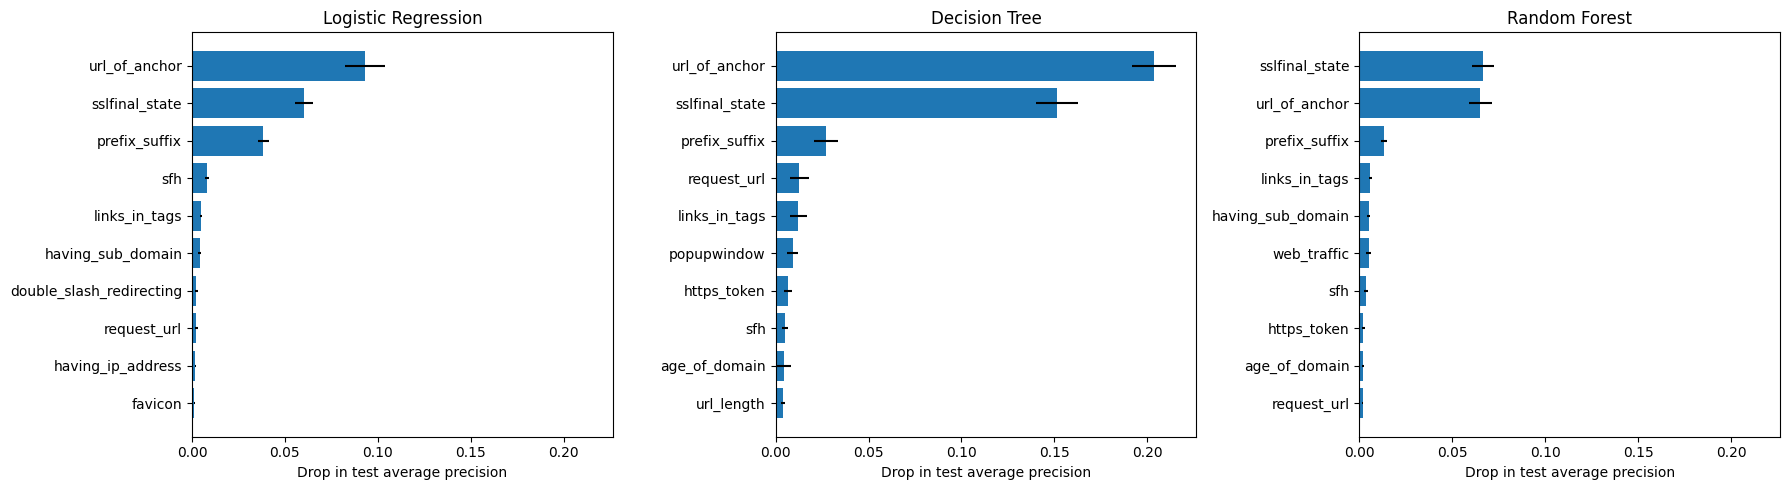

In [22]:
def permutation_importance_table(model, top_n=10):
    result = permutation_importance(
        model, X_test, y_test,
        scoring="average_precision",
        n_repeats=10,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    table = pd.DataFrame({
        "importance": result.importances_mean,
        "std": result.importances_std,
    }, index=feature_names)
    return table.sort_values("importance", ascending=False).head(top_n)


fig, axes = plt.subplots(1, len(best_models), figsize=(18, 5), sharex=True)

for ax, (name, model) in zip(axes, best_models.items()):
    table = permutation_importance_table(model).iloc[::-1]
    ax.barh(table.index, table["importance"], xerr=table["std"])
    ax.set_title(name)
    ax.set_xlabel("Drop in test average precision")

plt.tight_layout()
plt.show()

## 2. Logistic regression coefficients

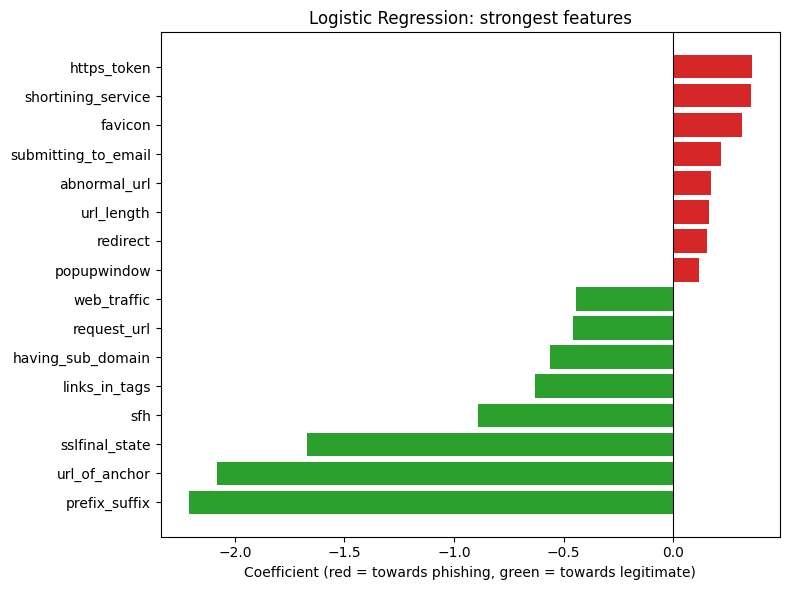

,coefficient,odds_ratio
https_token,0.359,1.432
shortining_service,0.355,1.426
favicon,0.312,1.366
submitting_to_email,0.219,1.244
abnormal_url,0.175,1.191
url_length,0.164,1.178
redirect,0.153,1.166
popupwindow,0.118,1.125
web_traffic,-0.444,0.641
request_url,-0.458,0.632


In [23]:
lr_model = best_models["Logistic Regression"].named_steps["model"]

coefficients = pd.DataFrame({
    "coefficient": lr_model.coef_[0],
    "odds_ratio": np.exp(lr_model.coef_[0]),
}, index=feature_names).sort_values("coefficient")

# Strongest 8 features in each direction
top = pd.concat([coefficients.head(8), coefficients.tail(8)])

colors = ["tab:green" if c < 0 else "tab:red" for c in top["coefficient"]]
plt.figure(figsize=(8, 6))
plt.barh(top.index, top["coefficient"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient (red = towards phishing, green = towards legitimate)")
plt.title("Logistic Regression: strongest features")
plt.tight_layout()
plt.show()

display(top.iloc[::-1].round(3))

## 3. Decision tree rules

|--- sslfinal_state <= 0.50
|   |--- url_of_anchor <= -0.50
|   |   |--- class: 1
|   |--- url_of_anchor >  -0.50
|   |   |--- links_in_tags <= -0.50
|   |   |   |--- prefix_suffix <= 0.00
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- prefix_suffix >  0.00
|   |   |   |   |--- class: 0
|   |   |--- links_in_tags >  -0.50
|   |   |   |--- prefix_suffix <= 0.00
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- prefix_suffix >  0.00
|   |   |   |   |--- class: 0
|--- sslfinal_state >  0.50
|   |--- url_of_anchor <= -0.50
|   |   |--- prefix_suffix <= 0.00
|   |   |   |--- links_in_tags <= -0.50
|   |   |   |   |--- class: 1
|   |   |   |--- links_in_tags >  -0.50
|   |   |   |   |--- truncated branch of depth 4
|   |   |--- prefix_suffix >  0.00
|   |   |   |--- class: 0
|   |--- url_of_anchor >  -0.50
|   |   |--- sfh <= -0.50
|   |   |   |--- prefix_suffix <= 0.00
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- prefix_suffix >  0.00


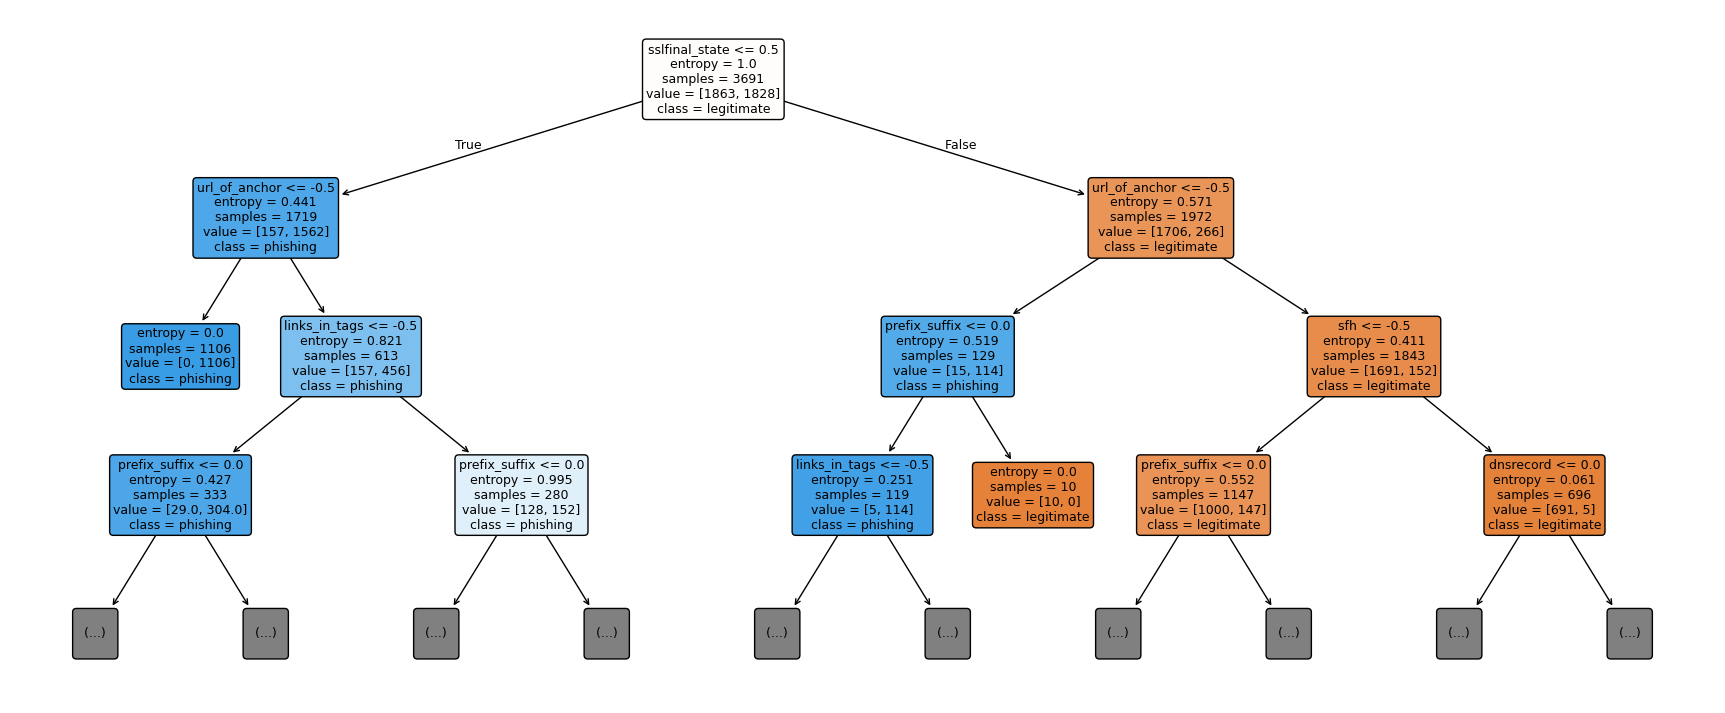

In [24]:
tree_model = best_models["Decision Tree"].named_steps["model"]

print(export_text(tree_model, feature_names=feature_names, max_depth=3))

fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=["legitimate", "phishing"],
    max_depth=3,
    filled=True,
    rounded=True,
    fontsize=9,
    ax=ax,
)
plt.show()

## 4. SHAP for the Random Forest

In [25]:
rf_model = best_models["Random Forest"].named_steps["model"]

# Explain a sample of the test set to keep this fast
X_shap = X_test.sample(n=min(500, len(X_test)), random_state=RANDOM_STATE)

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer(X_shap)

# Newer SHAP versions return one slice per class; keep the phishing class (index 1)
if shap_values.values.ndim == 3:
    shap_values = shap_values[:, :, 1]

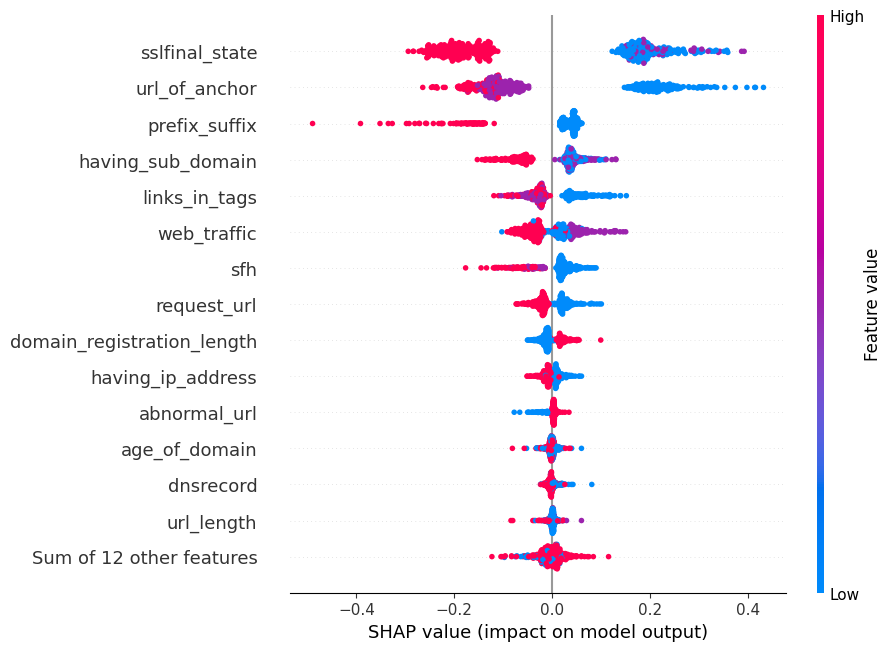

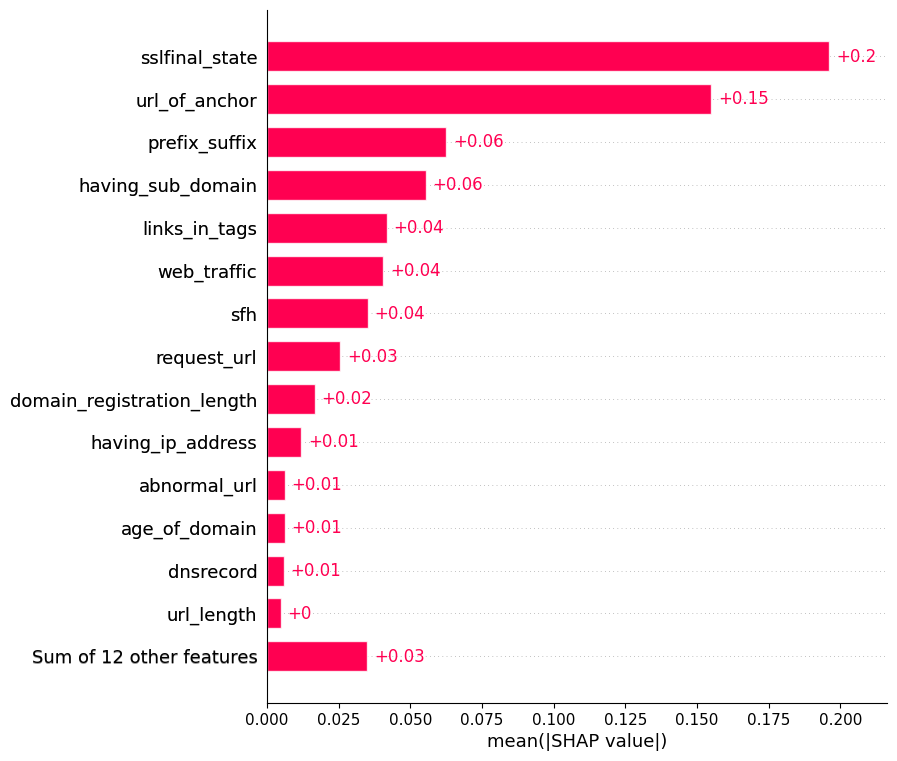

In [26]:
# Global view: which features matter and in which direction
shap.plots.beeswarm(shap_values, max_display=15)
shap.plots.bar(shap_values, max_display=15)

Most confident phishing: predicted phishing probability = 1.000 (actual: phishing)


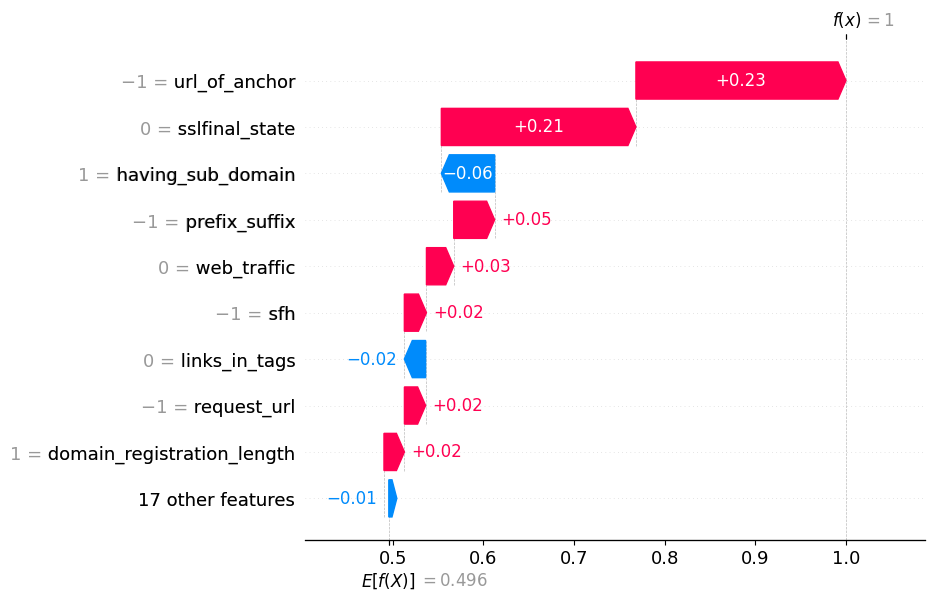

Most confident legitimate: predicted phishing probability = 0.000 (actual: legitimate)


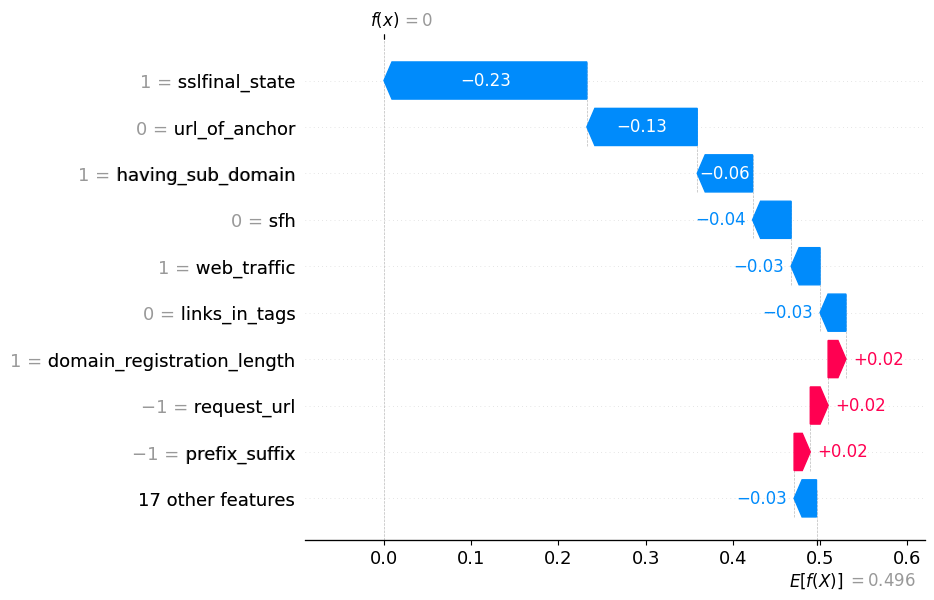

Closest to the decision boundary: predicted phishing probability = 0.490 (actual: phishing)


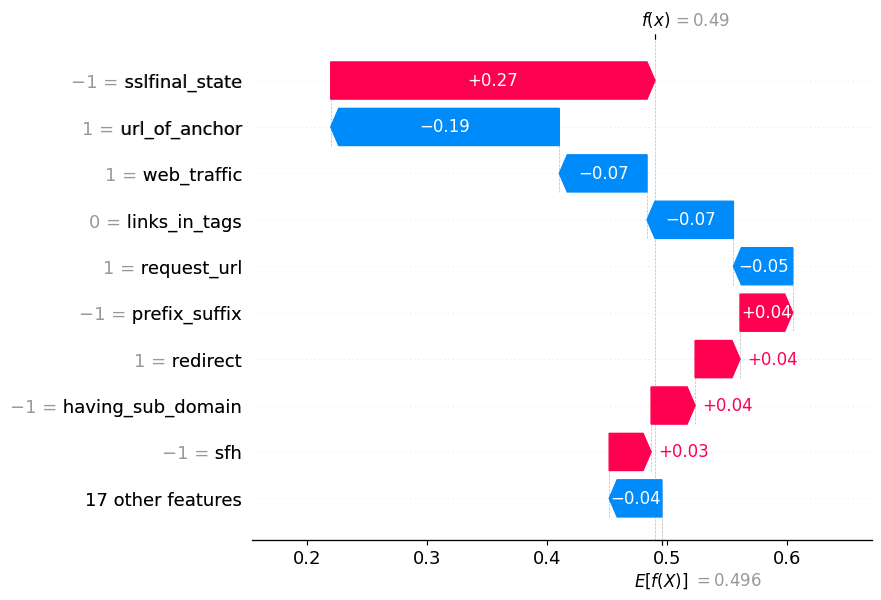

In [27]:
# Local view: explain individual websites
proba = rf_model.predict_proba(X_shap)[:, 1]

examples = {
    "Most confident phishing": int(np.argmax(proba)),
    "Most confident legitimate": int(np.argmin(proba)),
    "Closest to the decision boundary": int(np.argmin(np.abs(proba - 0.5))),
}

for title, i in examples.items():
    actual = "phishing" if y_test.loc[X_shap.index[i]] == 1 else "legitimate"
    print(f"{title}: predicted phishing probability = {proba[i]:.3f} (actual: {actual})")
    shap.plots.waterfall(shap_values[i], max_display=10)

### How to read the XAI output

- **Permutation importance**: a larger drop means the model relies more on that feature. If a feature's bar is near zero, shuffling it barely hurts the model.
- **Logistic regression**: the odds ratio is the multiplicative change in the odds of phishing for a one-standard-deviation increase in the feature.
- **SHAP beeswarm**: each dot is a website; red dots are high feature values, and dots to the right push the prediction towards phishing.
- **SHAP waterfall**: starts from the average prediction and shows how each feature moves one website's prediction up or down.

# Testing the Random Forest on live URLs

The model was trained on 26 precomputed features, so a raw URL has to be turned into those same features first. This section:

1. downloads **legitimate** URLs (Tranco top-sites list) and **phishing** URLs (OpenPhish feed), or reads your own files,
2. rebuilds the 26 features for each URL (URL text, the page's HTML, SSL, DNS, WHOIS),
3. scores them with the tuned Random Forest and compares the result with the earlier test-set performance.

**Read before running**
- Run this in Colab or a sandbox, not on a personal machine. It sends plain HTTP GET requests to live phishing pages (no JavaScript is executed, and nothing is downloaded beyond 2 MB per page).
- The features are re-implemented from the dataset's published rules, so they will not match the original 2015-era values exactly. Live accuracy can be lower than the test-set score for that reason alone, so the feature-distribution check at the end matters.
- Known deviations: `web_traffic` uses Tranco rank instead of the discontinued Alexa rank, and `sslfinal_state` checks for a valid certificate instead of a certificate older than one year (modern certificates are short-lived).
- Legitimate URLs from Tranco are home pages, while phishing URLs usually have long paths, so `url_length` will make the task look easier than it is. Pass your own `LEGIT_FILE` with full URLs to avoid this.

In [28]:
%pip install -q python-whois tldextract beautifulsoup4 tqdm

In [29]:
import io
import re
import socket
import ssl
import datetime as dt
from concurrent.futures import ThreadPoolExecutor, as_completed
from urllib.parse import urlparse, urljoin

import requests
import tldextract
import whois
import urllib3
from bs4 import BeautifulSoup
from tqdm.auto import tqdm
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score

urllib3.disable_warnings()   # pages are fetched with verify=False; SSL is checked separately

# ---------------- Settings ----------------
N_LEGIT = 500                    # legitimate URLs to test
N_PHISH = 500                    # phishing URLs to test
MAX_WORKERS = 16                 # parallel requests
REQUEST_TIMEOUT = 10             # seconds
UNKNOWN_WHOIS_VALUE = -1         # used when WHOIS fails (the original rules treat "no record" as phishing)
LEGIT_RANK_RANGE = (1, 100_000)  # which Tranco ranks to sample legitimate sites from

TRANCO_URL = "https://tranco-list.eu/top-1m.csv.zip"
OPENPHISH_URL = "https://openphish.com/feed.txt"

# Optional: your own lists (text files with one full URL per line); these replace the downloads
LEGIT_FILE = None
PHISH_FILE = None

In [30]:
def read_url_lines(path_or_url):
    if path_or_url.startswith("http"):
        text = requests.get(path_or_url, timeout=30).text
    else:
        text = open(path_or_url, encoding="utf-8").read()
    return pd.Series([l.strip() for l in text.splitlines() if l.strip().startswith("http")])


# Tranco top-1M: used both for legitimate URLs and for the web_traffic feature
tranco = pd.read_csv(
    io.BytesIO(requests.get(TRANCO_URL, timeout=60).content),
    compression="zip", names=["rank", "domain"],
)
tranco_rank = dict(zip(tranco["domain"], tranco["rank"]))

# Legitimate URLs
if LEGIT_FILE:
    legit_pool = read_url_lines(LEGIT_FILE)
else:
    low, high = LEGIT_RANK_RANGE
    in_range = tranco[tranco["rank"].between(low, high)]
    legit_pool = "https://" + in_range["domain"]

# Phishing URLs
phish_pool = read_url_lines(PHISH_FILE or OPENPHISH_URL).drop_duplicates()

legit_urls = legit_pool.sample(n=min(N_LEGIT, len(legit_pool)), random_state=RANDOM_STATE)
phish_urls = phish_pool.sample(n=min(N_PHISH, len(phish_pool)), random_state=RANDOM_STATE)

url_df = pd.concat([
    pd.DataFrame({"url": legit_urls.values, "label": 0}),
    pd.DataFrame({"url": phish_urls.values, "label": 1}),
], ignore_index=True)

print("URLs to test:")
print(url_df["label"].map({0: "legitimate", 1: "phishing"}).value_counts())

URLs to test:
label
legitimate    500
phishing      300
Name: count, dtype: int64


In [31]:
# ---------------- Feature extraction ----------------
_tld = tldextract.TLDExtract(suffix_list_urls=())   # bundled suffix list, no extra network calls
HEADERS = {"User-Agent": "Mozilla/5.0 (compatible; research-bot)"}
SHORTENERS = {
    "bit.ly", "goo.gl", "tinyurl.com", "t.co", "ow.ly", "is.gd", "buff.ly", "adf.ly",
    "bit.do", "cutt.ly", "rebrand.ly", "shorturl.at", "tiny.cc", "lnkd.in", "rb.gy", "v.gd", "t.ly",
}


def registered_domain(url_or_host):
    ext = _tld(url_or_host)
    return f"{ext.domain}.{ext.suffix}" if ext.suffix else ext.domain


def three_level(value, good_below, ok_up_to):
    """1 if value < good_below, 0 if value <= ok_up_to, else -1."""
    return 1 if value < good_below else 0 if value <= ok_up_to else -1


def lexical_features(url):
    parsed = urlparse(url)
    host = (parsed.hostname or "").lower()

    is_ip = bool(re.fullmatch(r"(\d{1,3}\.){3}\d{1,3}", host)
                 or re.fullmatch(r"0x[0-9a-f]+", host) or ":" in host)

    host_core = host[4:] if host.startswith("www.") else host
    if len(host_core.split(".")[-1]) == 2:           # drop a country-code TLD
        host_core = host_core.rsplit(".", 1)[0]
    dots = host_core.count(".")

    try:
        port = parsed.port
    except ValueError:
        port = -1

    return {
        "having_ip_address": -1 if is_ip else 1,
        "url_length": three_level(len(url), 54, 75),
        "shortining_service": -1 if host in SHORTENERS else 1,
        "having_at_symbol": -1 if "@" in url else 1,
        "double_slash_redirecting": -1 if url.rfind("//") > 7 else 1,
        "prefix_suffix": -1 if "-" in host else 1,
        "having_sub_domain": 1 if dots <= 1 else 0 if dots == 2 else -1,
        "port": -1 if port not in (None, 80, 443) else 1,
        "https_token": -1 if "https" in host else 1,
    }


def ssl_state(url):
    parsed = urlparse(url)
    if parsed.scheme != "https":
        return -1
    host, port = parsed.hostname, parsed.port or 443
    try:
        with socket.create_connection((host, port), timeout=REQUEST_TIMEOUT) as sock:
            with ssl.create_default_context().wrap_socket(sock, server_hostname=host):
                return 1                              # https with a valid, trusted certificate
    except (ssl.SSLError, ssl.CertificateError):
        return 0                                      # https, but the certificate is not trusted
    except OSError:
        return -1


def dns_record(host):
    try:
        socket.gethostbyname(host)
        return 1
    except OSError:
        return -1


def _to_datetime(value, pick):
    values = value if isinstance(value, list) else [value]
    values = [v.replace(tzinfo=None) for v in values if isinstance(v, dt.datetime)]
    return pick(values) if values else None


def whois_features(host):
    unknown = UNKNOWN_WHOIS_VALUE
    try:
        record = whois.whois(registered_domain(host))
        created = _to_datetime(record.creation_date, min)
        expires = _to_datetime(record.expiration_date, max)
        names = record.domain_name
        names = [n.lower() for n in (names if isinstance(names, list) else [names]) if n]
    except Exception:
        return {"domain_registration_length": unknown, "age_of_domain": unknown,
                "abnormal_url": unknown, "_whois_ok": False}

    now = dt.datetime.now()
    return {
        "domain_registration_length": unknown if expires is None else (1 if (expires - now).days > 365 else -1),
        "age_of_domain": unknown if created is None else (1 if (now - created).days >= 180 else -1),
        "abnormal_url": unknown if not names else (1 if any(n in host for n in names) else -1),
        "_whois_ok": bool(names and created and expires),
    }


def traffic_feature(host):
    rank = tranco_rank.get(registered_domain(host))
    return -1 if rank is None else 1 if rank <= 100_000 else 0


def fetch_page(url):
    """Return (html, final_url, number_of_redirects) or None if the page cannot be fetched."""
    try:
        r = requests.get(url, headers=HEADERS, timeout=REQUEST_TIMEOUT,
                         allow_redirects=True, stream=True, verify=False)
        raw = r.raw.read(2_000_000, decode_content=True)     # cap at 2 MB
        html = raw.decode(r.encoding or "utf-8", errors="ignore")
        final_url, n_redirects = r.url, len(r.history)
        r.close()
        return html, final_url, n_redirects
    except Exception:
        return None


def html_features(html, base_url):
    soup = BeautifulSoup(html, "html.parser")
    base_domain = registered_domain(base_url)

    def is_external(link):
        full = urljoin(base_url, link.strip())
        if urlparse(full).scheme not in ("http", "https"):
            return False
        return registered_domain(full) != base_domain

    def share(flags):
        return sum(flags) / len(flags) if flags else 0.0

    # favicon loaded from another domain
    icon = soup.find("link", rel=lambda v: v and "icon" in (" ".join(v) if isinstance(v, list) else v).lower())
    favicon = -1 if icon and icon.get("href") and is_external(icon["href"]) else 1

    # share of embedded objects (images, audio, video) hosted elsewhere
    objects = [t.get("src") for t in soup.find_all(["img", "audio", "video", "embed", "source"]) if t.get("src")]
    request_url = three_level(share([is_external(s) for s in objects]), 0.22, 0.61)

    # share of anchors that are empty, JavaScript, mailto or external
    hrefs = [a.get("href", "").strip() for a in soup.find_all("a", href=True)]
    unsafe = [h.lower() in ("", "#") or h.lower().startswith(("#", "javascript", "mailto")) or is_external(h)
              for h in hrefs]
    url_of_anchor = three_level(share(unsafe), 0.31, 0.67)

    # share of <meta>, <script>, <link> URLs hosted elsewhere
    tag_urls = [t.get("src") or t.get("href") or t.get("content") or ""
                for t in soup.find_all(["meta", "script", "link"])]
    tag_urls = [u for u in tag_urls if u.startswith(("http", "//"))]
    links_in_tags = three_level(share([is_external(u) for u in tag_urls]), 0.17, 0.81)

    # server form handler
    actions = [(f.get("action") or "").strip().lower() for f in soup.find_all("form")]
    if any(a in ("", "about:blank") for a in actions):
        sfh = -1
    elif any(a.startswith(("http", "//")) and is_external(a) for a in actions):
        sfh = 0
    else:
        sfh = 1

    hidden_iframe = any(
        str(f.get("frameborder", "")) == "0"
        or any(k in (f.get("style") or "").replace(" ", "").lower() for k in ("border:none", "display:none"))
        for f in soup.find_all("iframe")
    )

    return {
        "favicon": favicon,
        "request_url": request_url,
        "url_of_anchor": url_of_anchor,
        "links_in_tags": links_in_tags,
        "sfh": sfh,
        "submitting_to_email": -1 if any(a.startswith("mailto:") for a in actions) or "mail()" in html else 1,
        "on_mouseover": -1 if re.search(r"onmouseover\s*=\s*[\"']?\s*window\.status", html, re.I) else 1,
        "rightclick": -1 if re.search(r"event\.button\s*==\s*2", html) else 1,
        "popupwindow": -1 if re.search(r"\bprompt\s*\(", html) else 1,
        "iframe": -1 if hidden_iframe else 1,
    }


def extract_features(url):
    """All 26 model features for one URL, or None if the page could not be fetched."""
    try:
        page = fetch_page(url)
        if page is None:
            return None
        html, final_url, n_redirects = page
        host = (urlparse(url).hostname or "").lower()

        features = lexical_features(url)
        features["sslfinal_state"] = ssl_state(url)
        features.update(whois_features(host))
        features["dnsrecord"] = dns_record(host)
        features["web_traffic"] = traffic_feature(host)
        features["redirect"] = 1 if n_redirects <= 1 else 0
        features.update(html_features(html, final_url))
        return features
    except Exception:
        return None

In [32]:
# Run the extraction in parallel (this is the slow step: network, DNS and WHOIS lookups)
rows, failed = {}, []

with ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool:
    futures = {pool.submit(extract_features, url): url for url in url_df["url"]}
    for future in tqdm(as_completed(futures), total=len(futures)):
        result = future.result()
        if result is None:
            failed.append(futures[future])
        else:
            rows[futures[future]] = result

live_df = (
    url_df.drop_duplicates("url")
    .set_index("url")
    .join(pd.DataFrame.from_dict(rows, orient="index"), how="inner")
)

missing = set(feature_names) - set(live_df.columns)
assert not missing, f"Missing features: {missing}"

print("Pages that could not be fetched (dropped):")
print(url_df[url_df["url"].isin(failed)]["label"]
      .map({0: "legitimate", 1: "phishing"}).value_counts().to_string())
print("\nURLs scored:")
print(live_df["label"].map({0: "legitimate", 1: "phishing"}).value_counts().to_string())
print("\nWHOIS lookups that succeeded, by class:")
print(live_df.groupby("label")["_whois_ok"].mean().rename({0: "legitimate", 1: "phishing"}).round(3).to_string())

  0%|          | 0/800 [00:00<?, ?it/s]

ERROR:whois.whois:Error trying to connect to socket: closing socket - timed out
ERROR:whois.whois:Error trying to connect to socket: closing socket - [Errno 111] Connection refused
ERROR:whois.whois:Error trying to connect to socket: closing socket - timed out
ERROR:whois.whois:Error trying to connect to socket: closing socket - timed out
ERROR:whois.whois:Error trying to connect to socket: closing socket - [Errno -2] Name or service not known
ERROR:whois.whois:Error trying to connect to socket: closing socket - [Errno -2] Name or service not known
ERROR:whois.whois:Error trying to connect to socket: closing socket - [Errno -5] No address associated with hostname
ERROR:whois.whois:Error trying to connect to socket: closing socket - [Errno 111] Connection refused
ERROR:whois.whois:Error trying to connect to socket: closing socket - [Errno -2] Name or service not known
ERROR:whois.whois:Error trying to connect to socket: closing socket - [Errno 104] Connection reset by peer
ERROR:whois.w

Pages that could not be fetched (dropped):
label
legitimate    108
phishing        6

URLs scored:
label
legitimate    392
phishing      294

WHOIS lookups that succeeded, by class:
label
legitimate    0.834
phishing      0.156


              precision    recall  f1-score   support

  legitimate     0.8463    0.9974    0.9157       392
    phishing     0.9955    0.7585    0.8610       294

    accuracy                         0.8950       686
   macro avg     0.9209    0.8780    0.8883       686
weighted avg     0.9103    0.8950    0.8923       686

ROC-AUC:           0.9564
Average precision: 0.9573


,Predicted phishing,Predicted legitimate
Actual phishing,223,71
Actual legitimate,1,391


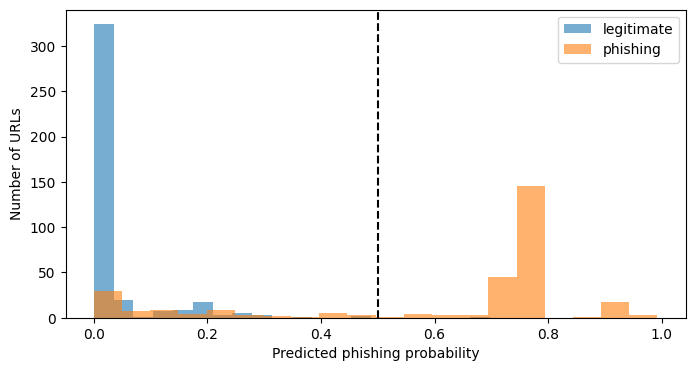

,label,phishing_probability,predicted,confidence
https://u.to/nUnhIg?ssxnxx.com,1,0.0000,0,0.5000
https://talibcodes.github.io/netflix-mini-project/,1,0.0000,0,0.5000
https://facebooklogin1234.blogspot.com/,1,0.0000,0,0.5000
https://jj-facebook.blogspot.com/,1,0.0025,0,0.4975
https://brad-facebook.blogspot.com/,1,0.0025,0,0.4975
https://comunicaciones365supp.vercel.app/,1,0.0025,0,0.4975
https://www.mercadolibre.com.pe/gz/account-verification?go=https%3A%2F%2Farticulo.mercadolibre.com.pe%2FMPE-833186620-zapatillas-adidas-urbano-street-talk-hombre-negro-jp8276-_JM%2F&tid=29e3f328-21a7-4745-bd50-33c513c47daf,1,0.0050,0,0.4950
https://lezgercomstrt.gitbook.io/,1,0.0050,0,0.4950
https://lezgercomstrt.gitbook.io/us,1,0.0050,0,0.4950
https://bitmartbit.com/m/,1,0.0075,0,0.4925


In [33]:
# Score the live URLs with the tuned Random Forest
rf_pipeline = searches["Random Forest"].best_estimator_

X_live = live_df[feature_names]
y_live = live_df["label"]

live_proba = rf_pipeline.predict_proba(X_live)[:, 1]
live_pred = (live_proba >= 0.5).astype(int)

print(classification_report(y_live, live_pred, target_names=["legitimate", "phishing"], digits=4))
print("ROC-AUC:          ", round(roc_auc_score(y_live, live_proba), 4))
print("Average precision:", round(average_precision_score(y_live, live_proba), 4))

display(pd.DataFrame(
    confusion_matrix(y_live, live_pred, labels=[1, 0]),
    index=["Actual phishing", "Actual legitimate"],
    columns=["Predicted phishing", "Predicted legitimate"],
))

# Phishing probability by true class
plt.figure(figsize=(8, 4))
plt.hist(live_proba[y_live == 0], bins=20, alpha=0.6, label="legitimate")
plt.hist(live_proba[y_live == 1], bins=20, alpha=0.6, label="phishing")
plt.axvline(0.5, color="black", linestyle="--")
plt.xlabel("Predicted phishing probability")
plt.ylabel("Number of URLs")
plt.legend()
plt.show()

# The most confident mistakes
results = live_df[["label"]].assign(phishing_probability=live_proba, predicted=live_pred)
mistakes = results[results["label"] != results["predicted"]]
mistakes = mistakes.assign(
    confidence=(mistakes["phishing_probability"] - 0.5).abs()
).sort_values("confidence", ascending=False)

pd.set_option("display.max_colwidth", 100)
display(mistakes.head(20))

In [34]:
# Do the rebuilt features behave like the training features?
train_means = X_train.groupby(y_train).mean().T      # columns: 0 = legitimate, 1 = phishing
live_means = X_live.groupby(y_live).mean().T

check = pd.DataFrame({
    "train legit": train_means[0],
    "train phish": train_means[1],
    "live legit": live_means[0],
    "live phish": live_means[1],
})
check["train gap"] = check["train phish"] - check["train legit"]
check["live gap"] = check["live phish"] - check["live legit"]

# Opposite sign = the feature may be coded the other way round in my re-implementation
check["possible mismatch"] = np.sign(check["train gap"]) * np.sign(check["live gap"]) < 0

display(check.round(2).sort_values("train gap"))
print("Features to double-check:", check.index[check["possible mismatch"]].tolist())

,train legit,train phish,live legit,live phish,train gap,live gap,possible mismatch
sslfinal_state,0.83,-0.46,0.97,0.67,-1.29,-0.30,False
url_of_anchor,0.39,-0.62,0.74,-0.62,-1.01,-1.36,False
prefix_suffix,-0.47,-1.00,0.88,-0.66,-0.53,-1.54,False
request_url,0.35,-0.15,0.70,-0.22,-0.50,-0.92,False
having_sub_domain,0.32,-0.14,1.00,0.12,-0.46,-0.88,False
web_traffic,0.46,0.01,1.00,0.76,-0.45,-0.24,False
sfh,-0.32,-0.76,0.72,0.87,-0.44,0.15,True
links_in_tags,0.03,-0.29,0.27,-0.73,-0.32,-1.00,False
having_ip_address,0.17,0.00,1.00,1.00,-0.17,0.00,False
age_of_domain,0.09,-0.01,0.67,-0.77,-0.10,-1.44,False


Features to double-check: ['domain_registration_length', 'favicon', 'sfh', 'abnormal_url']


In [41]:
def check_url(url):
    """Phishing probability for a single URL, plus the features the model saw."""
    features = extract_features(url)
    if features is None:
        print("Could not fetch the page, so the features cannot be built.")
        return None
    row = pd.DataFrame([features])[feature_names]
    probability = rf_pipeline.predict_proba(row)[0, 1]
    print(f"{url}\nPhishing probability: {probability:.3f} "
          f"-> {'PHISHING' if probability >= 0.5 else 'legitimate'}")
    return row.T.rename(columns={0: "value"})


# Example:
# check_url("https://www.wikipedia.org")
check_url("https://kafiil.com/")


https://kafiil.com/
Phishing probability: 0.030 -> legitimate


,value
having_ip_address,1
url_length,1
shortining_service,1
having_at_symbol,1
double_slash_redirecting,1
prefix_suffix,1
having_sub_domain,1
sslfinal_state,1
domain_registration_length,-1
favicon,1


### Reading the live results

- Compare the live precision, recall and ROC-AUC with the test-set numbers above. A large gap usually points to a feature mismatch (see the last table), to dataset age, or to the URL-length effect described at the top, rather than to the model alone.
- Dropped URLs are pages that could not be fetched. Many phishing pages are taken down within hours, so the phishing sample may be biased towards pages that survived.
- If WHOIS success differs a lot between the two classes, `UNKNOWN_WHOIS_VALUE` is influencing the result. Change it and re-run the scoring cell to see how sensitive the model is.